### Exercise 1 - create a classifier with >= 97% accuracy

In [13]:
from sklearn.datasets import fetch_openml

X, y = fetch_openml("mnist_784", version=1, as_frame=True, return_X_y=True)
X = X / 255.0
y = y.astype(int)

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [15]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier()

In [16]:
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

param_grid = {
    "n_neighbors": np.arange(3, 8),
    "weights": ["uniform", "distance"],
}
grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print(grid.best_params_, grid.best_score_)
print("test accuracy:", grid.score(X_test, y_test))

{'n_neighbors': np.int64(4), 'weights': 'distance'} 0.9705892646492343
test accuracy: 0.9731428571428572


### Exercise 2 - data augmentation

In [17]:
import numpy as np

def shift(image, direction):
    """Shift a 28x28 image by 1 pixel: 'up', 'down', 'left', or 'right'."""
    shifted = np.full_like(image, image[0, 0])
    if direction == "up":
        shifted[:-1, :] = image[1:, :]
    elif direction == "down":
        shifted[1:, :] = image[:-1, :]
    elif direction == "left":
        shifted[:, :-1] = image[:, 1:]
    elif direction == "right":
        shifted[:, 1:] = image[:, :-1]
    return shifted

In [18]:
# reshape the training rows into 28x28 images
X_train_images = X_train.to_numpy().reshape(-1, 28, 28)

# start with the originals, then add a copy of every image shifted 1 pixel in each direction
augmented = [X_train_images]
for direction in ["up", "down", "left", "right"]:
    augmented.append(np.array([shift(image, direction) for image in X_train_images]))

# flatten everything back to rows, and repeat the labels to match the 5 blocks of images
X_train_aug = np.concatenate(augmented).reshape(-1, 784)
y_train_aug = np.tile(y_train.to_numpy(), 5)

# retrain with the best parameters from the grid search and score on the untouched test set
model = KNeighborsClassifier(**grid.best_params_)
model.fit(X_train_aug, y_train_aug)
print("test accuracy:", model.score(X_test, y_test))

/Users/davidwinfield/Documents/homl/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(


test accuracy: 0.9797142857142858


/Users/davidwinfield/Documents/homl/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(


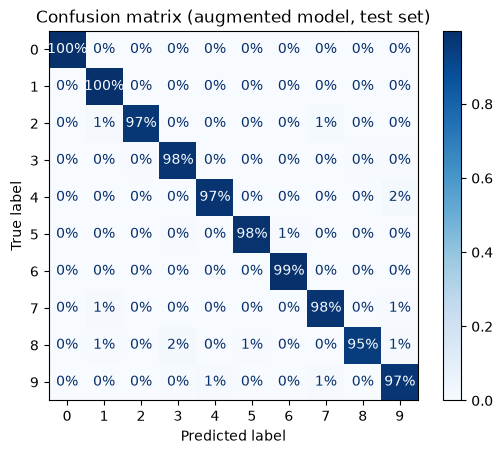

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# predict digits for the test set and plot how often each true digit gets each predicted label
y_pred = model.predict(X_test)

# normalize each row so every cell shows the percentage of that true digit
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", values_format=".0%", cmap="Blues")
plt.title("Confusion matrix (augmented model, test set)")
plt.show()